# Comparative Performance Analysis of ReLU and Tanh Activation Functions in Artificial Neural Networks for Breast Cancer Classification

**Tejas Bhandarkar · 2340173**  
CHRIST (Deemed to be University), Bengaluru · Department of Computer Science  
Deep Learning (CSC403-8) · CIA 1 – Component I A · 23 November 2026

**Research question.** On the same Wisconsin Diagnostic Breast Cancer test records, how do ReLU and Tanh hidden units affect malignant-class errors, ranking performance and sensitivity to training seed when all other training choices are held fixed?

This is an educational machine learning experiment. It has no clinical diagnostic use. The inputs are measurements extracted from images of fine-needle aspirates, and the output is a score for the dataset's recorded diagnosis. The notebook can be run independently from top to bottom. Each numerical result below is produced in the kernel.

## 1. Reproducible setup

The execution uses TensorFlow/Keras on CPU. Five seeds vary initialization and sample ordering. The first seed is designated in advance for detailed figures. Each pair shares the split, scaler, initial weights, epoch permutations, optimizer, stopping policy and decision threshold.

In [1]:
import argparse
import hashlib
import os
from pathlib import Path

# Configure a deterministic CPU run before importing TensorFlow.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()

SPLIT_SEEDS = (2026, 2027)
FIT_SEEDS = (11, 23, 37, 53, 71)
ACTIVATIONS = {"ReLU": "relu", "Tanh": "tanh"}
EXAMPLE_SEED = FIT_SEEDS[0]  # Chosen in advance for run-specific figures.
EPOCHS, PATIENCE, BATCH_SIZE = 50, 8, 16
THRESHOLD = 0.5
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]
LABELS = ["Benign", "Malignant"]
COLORS = {"ReLU": "#087C80", "Tanh": "#A54927"}
INK = "#193147"


from IPython.display import Image, Markdown, display
from importlib.metadata import version
import platform

ROOT = Path.cwd()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
print("Python", platform.python_version(), "| CPU", platform.machine())
for package in ["tensorflow-cpu", "keras", "scikit-learn", "numpy", "pandas",
                "matplotlib", "seaborn", "ipykernel", "nbclient"]:
    print(f"{package:16} {version(package)}")
print("Split seeds", SPLIT_SEEDS, "| Training seeds", FIT_SEEDS)

Python 3.12.14 | CPU x86_64
tensorflow-cpu   2.20.0
keras            3.15.1
scikit-learn     1.8.0
numpy            2.3.5
pandas           2.2.3
matplotlib       3.10.8
seaborn          0.13.2
ipykernel        7.4.0
nbclient         0.11.0
Split seeds (2026, 2027) | Training seeds (11, 23, 37, 53, 71)


## 2. Dataset and leakage control

The UCI Wisconsin Diagnostic Breast Cancer dataset is distributed in scikit-learn [1, 2]. Each record describes the cell nuclei in a digitized fine-needle aspirate image. Ten descriptors capture size, shape and texture: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. The mean, standard error and “worst” summary (mean of the three largest values) give 30 numeric features. The model receives neither an identifier nor the target as input.

The loader codes malignant as 0 and benign as 1. We explicitly reverse that coding so sigmoid output represents the malignant class. The initial stratified split reserves 20% for testing (seed 2026). A second split reserves 20% of the remainder for validation (seed 2027). Full-dataset checks below are structural. Feature distributions are explored only in training rows. The scaler learns a mean and population standard deviation for each feature using only those rows.

In [2]:
def prepare_data():
    """Return split arrays plus raw training measurements for descriptive EDA."""
    dataset = load_breast_cancer(as_frame=True)
    raw = dataset.data
    assert dataset.target_names.tolist() == ["malignant", "benign"]
    y = (dataset.target.to_numpy() == 0).astype("int32")
    ids = np.arange(len(y))
    pool, test = train_test_split(
        ids, test_size=0.20, random_state=SPLIT_SEEDS[0], stratify=y
    )
    train, valid = train_test_split(
        pool, test_size=0.20, random_state=SPLIT_SEEDS[1], stratify=y[pool]
    )
    splits = {"Train": train, "Validation": valid, "Test": test}
    assert np.array_equal(np.sort(np.concatenate(list(splits.values()))), ids)
    audit = {
        "samples": len(raw), "features": raw.shape[1],
        "missing_cells_including_label": int(dataset.frame.isna().sum().sum()),
        "duplicate_feature_rows": int(raw.duplicated().sum()),
        "duplicate_labeled_rows": int(dataset.frame.duplicated().sum()),
    }
    scaler = StandardScaler().fit(raw.iloc[train])
    assert scaler.n_samples_seen_ == len(train)
    arrays = {k: (scaler.transform(raw.iloc[idx]).astype("float32"), y[idx])
              for k, idx in splits.items()}
    assert np.allclose(arrays["Train"][0].mean(axis=0), 0, atol=1e-6)
    return raw, y, splits, arrays, audit, scaler


def split_table(y, splits):
    groups = {**splits, "All": np.arange(len(y))}
    return pd.DataFrame([
        {"partition": name, "rows": len(idx), "benign": int((y[idx] == 0).sum()),
         "malignant": int(y[idx].sum()), "malignant_fraction": y[idx].mean()}
        for name, idx in groups.items()
    ])
raw, y, splits, data, audit, scaler = prepare_data()
display(pd.Series(audit, name="value").to_frame())
display(split_table(y, splits).round(4))
print("Feature names:", ", ".join(raw.columns))

,value
samples,569
features,30
missing_cells_including_label,0
duplicate_feature_rows,0
duplicate_labeled_rows,0


,partition,rows,benign,malignant,malignant_fraction
0,Train,364,228,136,0.3736
1,Validation,91,57,34,0.3736
2,Test,114,72,42,0.3684
3,All,569,357,212,0.3726


Feature names: mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension, radius error, texture error, perimeter error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry, worst fractal dimension


### Training measurements

Histograms retain the raw units. Counts depend on class size, so compare ranges and location as well as heights. The table lists the per-class medians and the correlation table shows why some size measurements can be redundant.

,mean radius,mean concave points
diagnosis,,
Benign,11.995,0.02245
Malignant,17.570,0.08532


,mean radius,mean perimeter,mean area
mean radius,1.0000,0.9981,0.9865
mean perimeter,0.9981,1.0000,0.9863
mean area,0.9865,0.9863,1.0000


Training SD before scaling (population):
mean area          372.699274
mean smoothness      0.014456


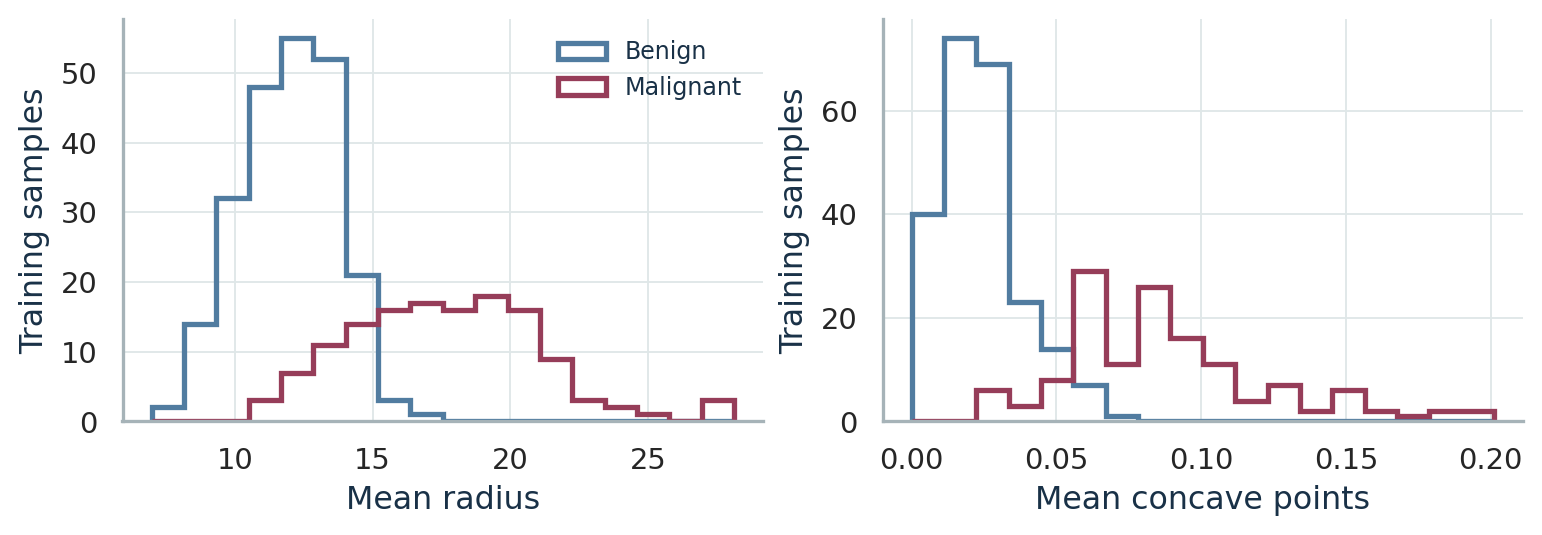

In [3]:
def figure_style():
    sns.set_theme(style="whitegrid", context="notebook",
                  rc={"font.family": "DejaVu Sans", "axes.labelcolor": INK,
                      "text.color": INK, "axes.edgecolor": "#A6B3B8",
                      "grid.color": "#DFE7E8", "grid.linewidth": 0.7,
                      "axes.spines.top": False, "axes.spines.right": False,
                      "legend.frameon": False, "savefig.facecolor": "white"})


def save(fig, directory, filename):
    fig.savefig(directory / filename, dpi=190, bbox_inches="tight", pad_inches=0.10)
    plt.close(fig)


def plot_eda(raw, y, train, directory):
    fig, axes = plt.subplots(1, 2, figsize=(8, 2.7), layout="constrained")
    for ax, feature, title in zip(axes, ["mean radius", "mean concave points"],
                                  ["Mean radius", "Mean concave points"]):
        values = raw[feature].to_numpy()[train]
        bins = np.histogram_bin_edges(values, bins=18)
        for i, color in [(0, "#517CA0"), (1, "#963D59")]:
            ax.hist(values[y[train] == i], bins=bins, histtype="step", linewidth=2,
                    color=color, label=LABELS[i])
        ax.set(xlabel=title, ylabel="Training samples")
    axes[0].legend(fontsize=9)
    save(fig, directory, "01_training_distributions.png")
figure_style()
tr = splits["Train"]
training = raw.iloc[tr]
class_names = pd.Series(np.asarray(LABELS)[y[tr]], index=training.index, name="diagnosis")
display(training.groupby(class_names)[["mean radius", "mean concave points"]].median().round(5))
display(training[["mean radius", "mean perimeter", "mean area"]].corr().round(4))
print("Training SD before scaling (population):")
print(training[["mean area", "mean smoothness"]].std(ddof=0).to_string())
plot_eda(raw, y, tr, FIGURES)
display(Image(filename=str(FIGURES / "01_training_distributions.png"), width=775))

The malignant group has larger median mean radius and mean concave points in this training partition. The histograms overlap, which makes a single-feature threshold an imperfect rule. The high correlation between radius and perimeter means interpreting one learned weight in isolation would be misleading.

## 3. Mathematical model

For a neuron receiving activations $a_i$, the preactivation is $z_j=\sum_i w_{ji}a_i+b_j$. The weights give signed contributions from the inputs. The bias shifts the transition point even if all inputs are zero. Standardization uses $x'_i=(x_i-\mu_{i,\mathrm{train}})/s_{i,\mathrm{train}}$.

Using column-vector notation, the forward pass is
$$a^{(0)}=x',\quad z^{(\ell)}=W^{(\ell)}a^{(\ell-1)}+b^{(\ell)}.$$
The hidden activations are $a^{(1)}=g(z^{(1)})$ and $a^{(2)}=g(z^{(2)})$. The two hidden layers share the choice of $g$. Their weights are learned independently.

| Function | Definition | Derivative | Role |
|---|---|---|---|
| ReLU | $g(z)=\max(0,z)$ | $1$ for $z>0$, $0$ for $z<0$ | A positive input has unit slope. We use the zero subgradient at the origin. |
| Tanh | $g(z)=(e^z-e^{-z})/(e^z+e^{-z})$ | $1-g(z)^2$ | Signed output is bounded. Large absolute inputs yield small gradients. |
| Sigmoid | $p=\sigma(z^{(3)})=1/(1+e^{-z^{(3)}})$ | $p(1-p)$ | Maps the final scalar to a malignant-class score in $(0,1)$. |

For a minibatch of $m$ records, binary cross-entropy is
$$J=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right].$$
For a malignant record ($y=1$), a small $p$ incurs a large loss. BCE therefore distinguishes the confidence of predictions that get the same hard label.

### Backpropagation and weight updates

For a single example with loss $L$, applying the chain rule at the output gives
$$\delta^{(3)}=\frac{\partial L}{\partial z^{(3)}}=
\left(-\frac{y}{p}+\frac{1-y}{1-p}\right)p(1-p)=p-y.$$
For hidden layers $\ell=2,1$,
$$\delta^{(\ell)}=((W^{(\ell+1)})^\top\delta^{(\ell+1)})\odot g'(z^{(\ell)}).$$
For one example, $\partial L/\partial W^{(\ell)}=\delta^{(\ell)}(a^{(\ell-1)})^\top$ and $\partial L/\partial b^{(\ell)}=\delta^{(\ell)}$. Average these gradients over the minibatch. A basic gradient step is $\theta_t=\theta_{t-1}-\eta g_t$ with $g_t=\nabla_\theta J$. The implementation uses Adam [3, 4]. Its moment estimates are
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$
In the Keras epsilon-hat form [5], let $\alpha_t=\eta\sqrt{1-\beta_2^t}/(1-\beta_1^t)$. Then $\theta_t=\theta_{t-1}-\alpha_tm_t/(\sqrt{v_t}+\hat\epsilon)$. Squaring, square roots and division are elementwise. Both moment estimates start at zero.

## 4. Network design

The input is a fixed-length vector of numeric descriptors. Two dense hidden layers can learn interactions between those descriptors, and the 16-to-8 bottleneck keeps the parameter count modest. Nonlinear activations allow the two layers to form a decision boundary more flexible than a single linear transformation. A single sigmoid suits the two mutually exclusive labels. Changing only the hidden activation makes the paired comparison interpretable.

Model: "MLP_ReLU"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ malignant_probability (Dense)   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 641 (2.50 KB)
 Trainable params: 641 (2.50 KB)
 Non-trainable params: 0 (0.00 B)


Model: "MLP_Tanh"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ malignant_probability (Dense)   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 641 (2.50 KB)
 Trainable params: 641 (2.50 KB)
 Non-trainable params: 0 (0.00 B)


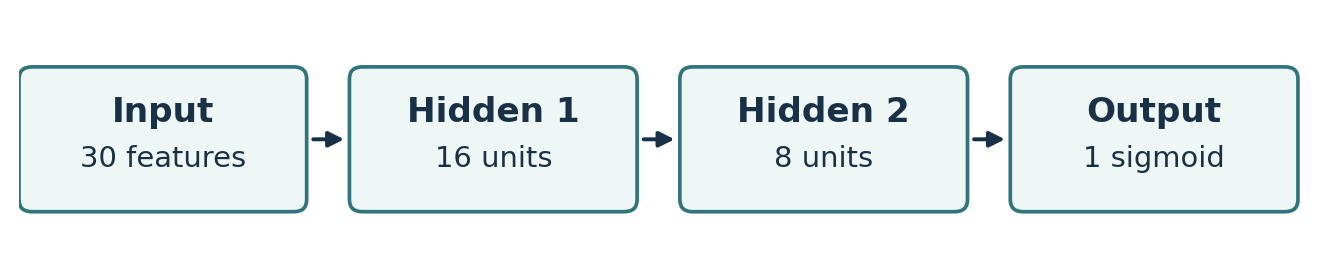

In [4]:
def make_model(label, seed):
    """Identical seeded Glorot kernels and zero biases within each paired run."""
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential(name=f"MLP_{label}")
    model.add(tf.keras.Input(shape=(30,), name="measurements"))
    for i, (units, activation, name) in enumerate([
        (16, ACTIVATIONS[label], "hidden_1"), (8, ACTIVATIONS[label], "hidden_2"),
        (1, "sigmoid", "malignant_probability")
    ]):
        model.add(tf.keras.layers.Dense(
            units, activation=activation, name=name,
            kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed + i),
            bias_initializer="zeros",
        ))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9,
                                           beta_2=0.999, epsilon=1e-7),
        loss=tf.keras.losses.BinaryCrossentropy(), jit_compile=False,
    )
    assert model.count_params() == 641
    return model


def weight_digest(model):
    return hashlib.sha256(b"".join(w.tobytes() for w in model.get_weights())).hexdigest()


def plot_architecture(directory):
    fig, ax = plt.subplots(figsize=(8.8, 1.65))
    ax.set(xlim=(0, 10), ylim=(0, 2))
    ax.axis("off")
    blocks = [(0.05, "Input", "30 features"), (2.6, "Hidden 1", "16 units"),
              (5.15, "Hidden 2", "8 units"), (7.7, "Output", "1 sigmoid")]
    for i, (x, title, subtitle) in enumerate(blocks):
        box = FancyBboxPatch((x, 0.45), 2.12, 1.1, boxstyle="round,pad=0.05,rounding_size=0.1",
                             edgecolor="#32747B", facecolor="#EFF7F6", linewidth=1.4)
        ax.add_patch(box)
        ax.text(x+1.06, 1.15, title, ha="center", weight="bold", fontsize=13)
        ax.text(x+1.06, 0.77, subtitle, ha="center", fontsize=11)
        if i < 3:
            ax.annotate("", xy=(x+2.5, 1), xytext=(x+2.18, 1),
                        arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5))
    save(fig, directory, "02_ann_architecture.png")
for label in ACTIVATIONS:
    lines = []
    make_model(label, EXAMPLE_SEED).summary(print_fn=lines.append)
    display({"text/plain": chr(10).join(lines)}, raw=True)
plot_architecture(FIGURES)
display(Image(filename=str(FIGURES / "02_ann_architecture.png"), width=760))

## 5. Paired training

Both runs for a seed receive identical Glorot-uniform weights, zero biases and the same epoch permutations. A SHA-256 check verifies the initial parameters match. Adam uses a learning rate of 0.001, β₁ = 0.9, β₂ = 0.999 and ε̂ = 10⁻⁷. Each batch contains up to 16 examples. The last partial batch is retained. Training ends at 50 epochs or after eight consecutive epochs without a strictly lower validation BCE. Only validation BCE selects the restored weights. Training and validation curves are measured from the same end-of-epoch weights.

All ten fits finish before test predictions are computed.

In [5]:
def fit_one(label, seed, orders, train, valid):
    """Train on minibatches; score full partitions at the end of each epoch."""
    model = make_model(label, seed)
    initial_digest = weight_digest(model)
    x_train, y_train = train
    bce = tf.keras.losses.BinaryCrossentropy()

    def epoch_scores(x, y):
        probabilities = model(x, training=False)
        loss = float(bce(y[:, None], probabilities).numpy())
        accuracy = np.mean((probabilities.numpy().ravel() >= THRESHOLD) == y)
        return loss, float(accuracy)

    best_loss = float("inf")
    history = []
    for epoch, order in enumerate(orders, start=1):
        for start in range(0, len(order), BATCH_SIZE):
            idx = order[start:start + BATCH_SIZE]
            model.train_on_batch(x_train[idx], y_train[idx, None])
        loss, accuracy = epoch_scores(*train)
        val_loss, val_accuracy = epoch_scores(*valid)
        history.append(dict(activation=label, seed=seed, epoch=epoch, loss=loss,
                            accuracy=accuracy, val_loss=val_loss, val_accuracy=val_accuracy))
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_weights = model.get_weights()
        if epoch - best_epoch >= PATIENCE:
            break
    model.set_weights(best_weights)
    assert np.isclose(epoch_scores(*valid)[0], best_loss)
    info = dict(activation=label, seed=seed, epochs_run=epoch, best_epoch=best_epoch,
                best_val_loss=best_loss, initial_weight_sha256=initial_digest)
    return model, history, info


def train_all(train, valid):
    """This stage accepts only training and validation arrays."""
    fits, histories, checkpoints = [], [], []
    for seed in FIT_SEEDS:
        rng = np.random.default_rng(seed)
        # Both activations consume the same ordered sequence, up to early stopping.
        orders = [rng.permutation(len(train[1])) for _ in range(EPOCHS)]
        pair_digests = []
        for label in ACTIVATIONS:
            model, history, info = fit_one(label, seed, orders, train, valid)
            pair_digests.append(info["initial_weight_sha256"])
            fits.append((label, seed, model))
            histories.extend(history)
            checkpoints.append(info)
            print(f"{label:4}  seed {seed:2}  epochs {info['epochs_run']:2}  "
                  f"restored {info['best_epoch']:2}  validation BCE {info['best_val_loss']:.5f}")
        assert pair_digests[0] == pair_digests[1]
    return fits, pd.DataFrame(histories), pd.DataFrame(checkpoints)
fits, history, checkpoints = train_all(data["Train"], data["Validation"])
display(checkpoints.drop(columns="initial_weight_sha256").round(5))

ReLU  seed 11  epochs 50  restored 50  validation BCE 0.07961


Tanh  seed 11  epochs 49  restored 41  validation BCE 0.08086


ReLU  seed 23  epochs 50  restored 46  validation BCE 0.07627


Tanh  seed 23  epochs 42  restored 34  validation BCE 0.08104


ReLU  seed 37  epochs 50  restored 50  validation BCE 0.08088


Tanh  seed 37  epochs 50  restored 46  validation BCE 0.08297


ReLU  seed 53  epochs 32  restored 24  validation BCE 0.11007


Tanh  seed 53  epochs 50  restored 43  validation BCE 0.07725


ReLU  seed 71  epochs 50  restored 49  validation BCE 0.08840


Tanh  seed 71  epochs 50  restored 50  validation BCE 0.06946


,activation,seed,epochs_run,best_epoch,best_val_loss
0,ReLU,11,50,50,0.07961
1,Tanh,11,49,41,0.08086
2,ReLU,23,50,46,0.07627
3,Tanh,23,42,34,0.08104
4,ReLU,37,50,50,0.08088
5,Tanh,37,50,46,0.08297
6,ReLU,53,32,24,0.11007
7,Tanh,53,50,43,0.07725
8,ReLU,71,50,49,0.08840
9,Tanh,71,50,50,0.06946


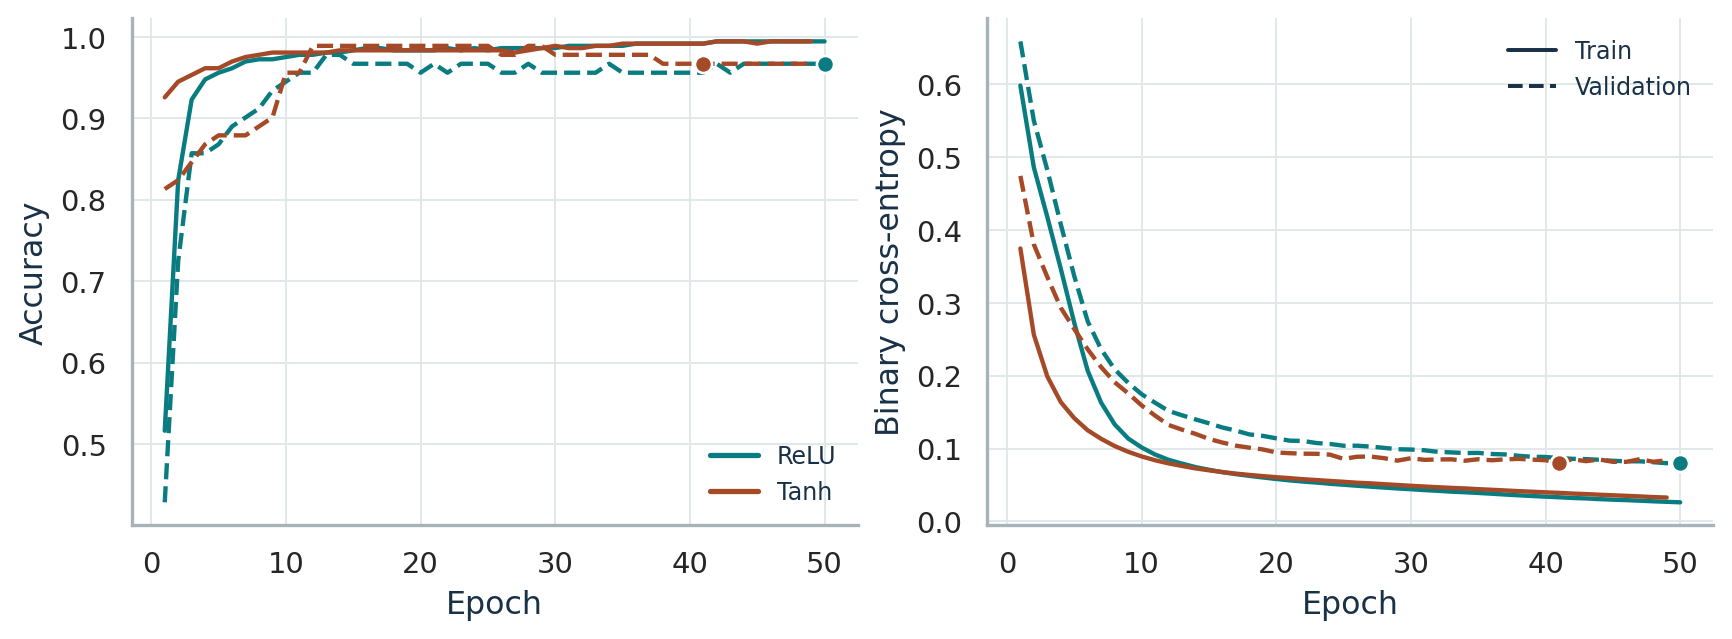

,activation,seed,epoch,loss,accuracy,val_loss,val_accuracy
0,ReLU,11,1,0.5985,0.5165,0.6591,0.4286
9,ReLU,11,10,0.1016,0.9753,0.1747,0.9451
19,ReLU,11,20,0.0582,0.9835,0.1141,0.9560
29,ReLU,11,30,0.0442,0.9863,0.0987,0.9560
39,ReLU,11,40,0.0340,0.9918,0.0885,0.9560
49,ReLU,11,50,0.0262,0.9945,0.0796,0.9670
50,Tanh,11,1,0.3748,0.9258,0.4744,0.8132
59,Tanh,11,10,0.0892,0.9808,0.1594,0.9560
69,Tanh,11,20,0.0607,0.9835,0.0946,0.9890
79,Tanh,11,30,0.0489,0.9890,0.0867,0.9780


In [6]:
def plot_curves(history, checkpoints, directory):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.25), layout="constrained")
    for label, color in COLORS.items():
        h = history.query("seed == @EXAMPLE_SEED and activation == @label")
        best = checkpoints.query("seed == @EXAMPLE_SEED and activation == @label").iloc[0].best_epoch
        for ax, metric, title in zip(axes, ["accuracy", "loss"], ["Accuracy", "Binary cross-entropy"]):
            ax.plot(h.epoch, h[metric], color=color, lw=1.65)
            ax.plot(h.epoch, h["val_"+metric], color=color, linestyle="--", lw=1.65)
            point = h[h.epoch == best].iloc[0]
            ax.scatter(best, point["val_"+metric], s=42, color=color, edgecolors="white", zorder=4)
            ax.set(xlabel="Epoch", ylabel=title)
    axes[0].legend(handles=[Line2D([], [], color=c, label=l, lw=2) for l, c in COLORS.items()],
                   loc="lower right", fontsize=9)
    axes[1].legend(handles=[Line2D([], [], color=INK, ls=ls, label=l)
                            for l, ls in [("Train", "-"), ("Validation", "--")]],
                   loc="upper right", fontsize=9)
    save(fig, directory, "03_learning_curves.png")
plot_curves(history, checkpoints, FIGURES)
display(Image(filename=str(FIGURES / "03_learning_curves.png"), width=830))
display(history.query("seed == @EXAMPLE_SEED and (epoch == 1 or epoch % 10 == 0)").round(4))

The markers show restored epochs on the validation traces. Accuracy can plateau while BCE keeps moving because changing the confidence of a prediction need not move it across 0.5. The history CSV includes every observed epoch for every fit.

## 6. Held-out evaluation

A score of at least 0.5 predicts malignant. For malignant as positive, precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2TP/(2TP+FP+FN), and accuracy = (TP+TN)/N. ROC-AUC summarizes ranking over all thresholds. The table uses arithmetic means and sample standard deviations (divisor 4) across the five runs per activation. The test records are shared, so these deviations describe training-seed variability on one split.

In [7]:
def evaluate(fits, test, test_ids):
    """Score each frozen fit on exactly the same untouched test set."""
    x_test, actual = test
    runs, predictions, reports = [], [], []
    for label, seed, model in fits:
        prob = model(x_test, training=False).numpy().ravel()
        pred = (prob >= THRESHOLD).astype(int)
        tn, fp, fn, tp = confusion_matrix(actual, pred, labels=[0, 1]).ravel()
        runs.append(dict(activation=label, seed=seed, accuracy=accuracy_score(actual, pred),
                         precision=precision_score(actual, pred), recall=recall_score(actual, pred),
                         f1=f1_score(actual, pred), roc_auc=roc_auc_score(actual, prob),
                         tn=tn, fp=fp, fn=fn, tp=tp))
        predictions.append(pd.DataFrame(dict(activation=label, seed=seed, row_id=test_ids,
                                            target=actual, probability=prob.astype(float), predicted=pred)))
        report = classification_report(actual, pred, labels=[0, 1], target_names=LABELS,
                                       output_dict=True, zero_division=0)
        for row in [*LABELS, "macro avg", "weighted avg"]:
            reports.append(dict(activation=label, seed=seed, group=row, **report[row]))
    per_run = pd.DataFrame(runs)
    grouped = per_run.groupby("activation", sort=False)
    summary = pd.concat([grouped[m].agg(["mean", "std"]).add_prefix(m + "_")
                         for m in METRICS], axis=1).reset_index()
    return per_run, summary, pd.concat(predictions, ignore_index=True), pd.DataFrame(reports)


def save_tables(directory, splits, y, history, checkpoints, runs, summary, predictions, reports):
    directory.mkdir(parents=True, exist_ok=True)
    membership = pd.concat([pd.DataFrame(dict(row_id=idx, partition=k, target=y[idx]))
                            for k, idx in splits.items()]).sort_values("row_id")
    tables = {"split_membership": membership, "training_history": history,
              "per_run_metrics": runs.merge(checkpoints, on=["activation", "seed"], validate="1:1"),
              "comparison_metrics": summary, "test_predictions": predictions,
              "classification_reports": reports}
    for name, frame in tables.items():
        frame.to_csv(directory / f"{name}.csv", index=False, float_format="%.12g")
runs, summary, predictions, reports = evaluate(fits, data["Test"], splits["Test"])
save_tables(ROOT / "results", splits, y, history, checkpoints, runs, summary, predictions, reports)
display(runs.round(4))
metric_table = pd.DataFrame({
    label: [f"{row[m+'_mean']:.4f} ± {row[m+'_std']:.4f}" for m in METRICS]
    for label, row in summary.set_index("activation").iterrows()
}, index=["Accuracy", "Malignant precision", "Malignant recall", "Malignant F1", "ROC-AUC"])
display(metric_table)

,activation,seed,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,ReLU,11,0.9561,0.9111,0.9762,0.9425,0.9940,68,4,1,41
1,Tanh,11,0.9474,0.9286,0.9286,0.9286,0.9960,69,3,3,39
2,ReLU,23,0.9649,0.9318,0.9762,0.9535,0.9970,69,3,1,41
3,Tanh,23,0.9825,1.0000,0.9524,0.9756,0.9990,72,0,2,40
4,ReLU,37,0.9474,0.9286,0.9286,0.9286,0.9964,69,3,3,39
5,Tanh,37,0.9649,0.9750,0.9286,0.9512,0.9964,71,1,3,39
6,ReLU,53,0.9737,0.9756,0.9524,0.9639,0.9970,71,1,2,40
7,Tanh,53,0.9474,0.9286,0.9286,0.9286,0.9947,69,3,3,39
8,ReLU,71,0.9737,0.9535,0.9762,0.9647,0.9990,70,2,1,41
9,Tanh,71,0.9649,0.9750,0.9286,0.9512,0.9967,71,1,3,39


,ReLU,Tanh
Accuracy,0.9632 ± 0.0114,0.9614 ± 0.0147
Malignant precision,0.9401 ± 0.0249,0.9614 ± 0.0317
Malignant recall,0.9619 ± 0.0213,0.9333 ± 0.0106
Malignant F1,0.9506 ± 0.0153,0.9470 ± 0.0196
ROC-AUC,0.9967 ± 0.0018,0.9966 ± 0.0016


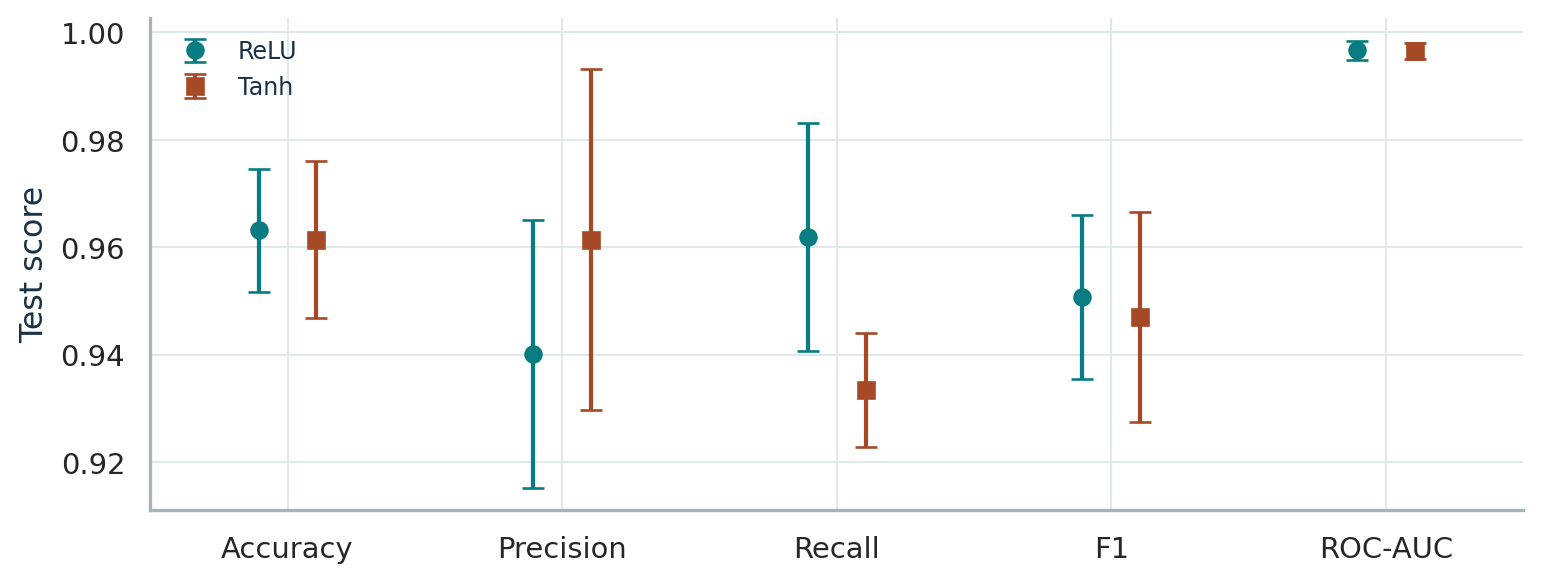

In [8]:
def plot_comparison(summary, directory):
    fig, ax = plt.subplots(figsize=(8, 2.95), layout="constrained")
    for i, (label, color) in enumerate(COLORS.items()):
        row = summary.set_index("activation").loc[label]
        ax.errorbar(np.arange(5) + (i-.5)*.21, [row[m+"_mean"] for m in METRICS],
                    yerr=[row[m+"_std"] for m in METRICS], fmt="o" if i == 0 else "s",
                    color=color, capsize=4, ms=6, elinewidth=1.6, label=label)
    ax.set_xticks(range(5), ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
    ax.set(ylabel="Test score", xlim=(-.5, 4.5))
    ax.legend(loc="best", fontsize=9)
    save(fig, directory, "06_metric_comparison.png")
plot_comparison(summary, FIGURES)
display(Image(filename=str(FIGURES / "06_metric_comparison.png"), width=760))

### Confusion matrices and class-specific metrics

Rows of each matrix show the recorded class and columns show the predicted class. The lower-left cell counts malignant samples classified as benign. The tables below give both classes equal visibility. The macro average gives each class equal weight, and the weighted average uses its test support.

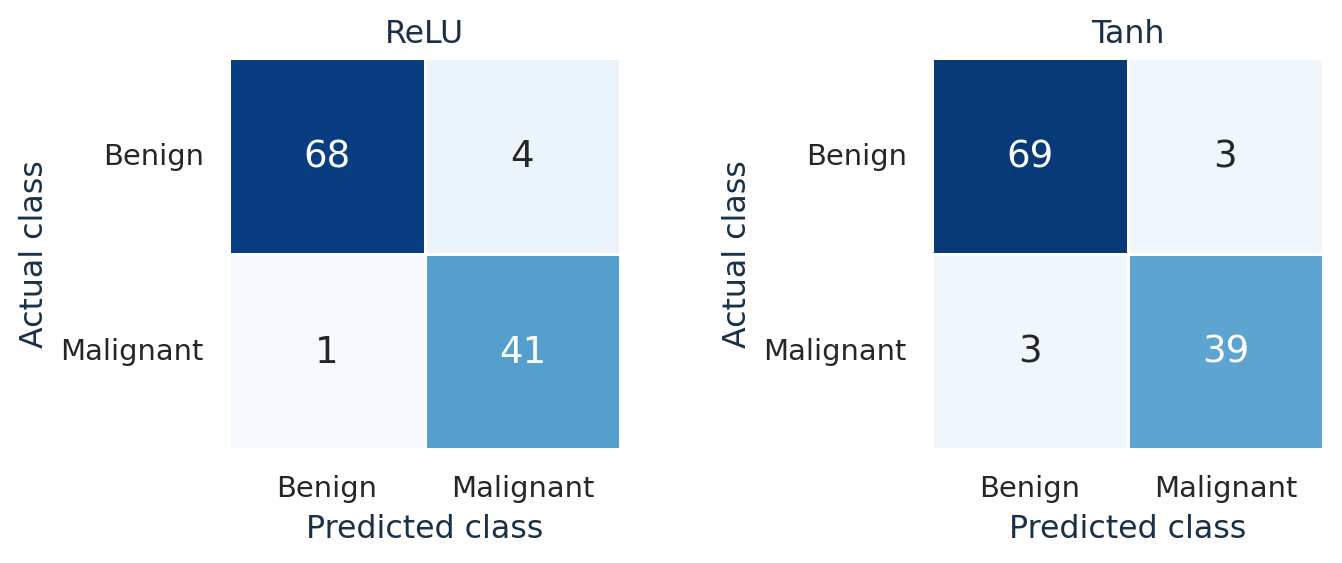

ReLU | seed 11


,precision,recall,f1-score,support
group,,,,
Benign,0.9855,0.9444,0.9645,72.0
Malignant,0.9111,0.9762,0.9425,42.0
macro avg,0.9483,0.9603,0.9535,114.0
weighted avg,0.9581,0.9561,0.9564,114.0


Tanh | seed 11


,precision,recall,f1-score,support
group,,,,
Benign,0.9583,0.9583,0.9583,72.0
Malignant,0.9286,0.9286,0.9286,42.0
macro avg,0.9435,0.9435,0.9435,114.0
weighted avg,0.9474,0.9474,0.9474,114.0


In [9]:
def plot_confusions(predictions, directory):
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.85), layout="constrained")
    for ax, label in zip(axes, ACTIVATIONS):
        d = predictions.query("seed == @EXAMPLE_SEED and activation == @label")
        cm = confusion_matrix(d.target, d.predicted, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cbar=False, square=True, cmap="Blues",
                    vmin=0, vmax=d.target.value_counts().max(), ax=ax, linewidths=1,
                    xticklabels=LABELS, yticklabels=LABELS, annot_kws={"fontsize": 14})
        ax.set(xlabel="Predicted class", ylabel="Actual class", title=label)
        ax.tick_params(axis="y", labelrotation=0)
    save(fig, directory, "04_confusion_matrices.png")
plot_confusions(predictions, FIGURES)
display(Image(filename=str(FIGURES / "04_confusion_matrices.png"), width=730))
for label in ACTIVATIONS:
    print(label, "| seed", EXAMPLE_SEED)
    display(reports.query("activation == @label and seed == @EXAMPLE_SEED")
            .set_index("group")[["precision", "recall", "f1-score", "support"]].round(4))

### Receiver operating characteristic

The ROC curve plots TPR = TP/(TP+FN) against FPR = FP/(FP+TN) as the threshold sweeps through the scores. The right panel magnifies low false-positive rates. The diagonal in the left panel is the random-ranking reference.

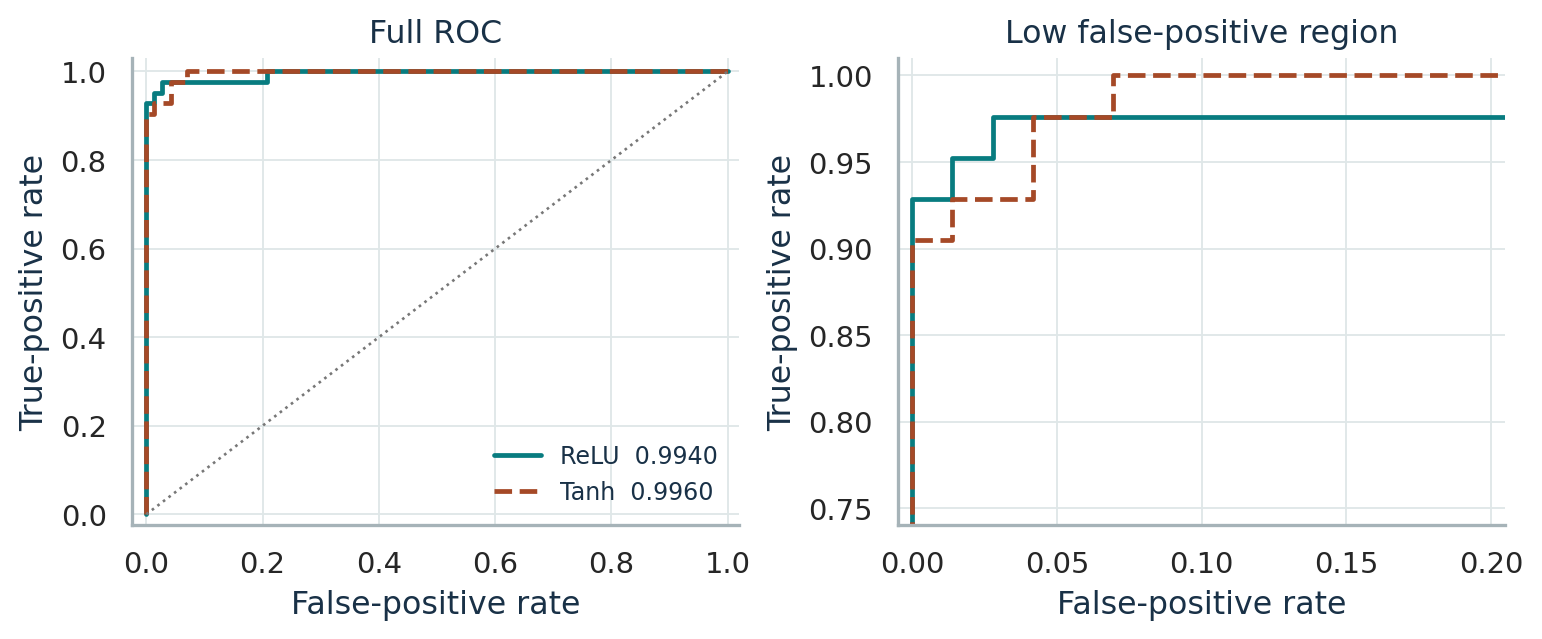

In [10]:
def plot_roc(predictions, directory):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.25), layout="constrained")
    for ax in axes:
        for label, color in COLORS.items():
            d = predictions.query("seed == @EXAMPLE_SEED and activation == @label")
            fpr, tpr, _ = roc_curve(d.target, d.probability, drop_intermediate=False)
            auc = roc_auc_score(d.target, d.probability)
            ax.step(fpr, tpr, where="post", c=color,
                    ls="-" if label == "ReLU" else "--", lw=1.8, label=f"{label}  {auc:.4f}")
        ax.set(xlabel="False-positive rate", ylabel="True-positive rate")
    axes[0].plot([0, 1], [0, 1], ":", color="#777777", lw=1)
    axes[0].set(xlim=(-0.025, 1.02), ylim=(-0.025, 1.03), title="Full ROC")
    axes[1].set(xlim=(-0.005, .205), ylim=(.74, 1.01), title="Low false-positive region")
    axes[0].legend(loc="lower right", fontsize=9)
    save(fig, directory, "05_roc_curves.png")
plot_roc(predictions, FIGURES)
display(Image(filename=str(FIGURES / "05_roc_curves.png"), width=760))

## 7. Experimental interpretation

In [11]:
means = summary.set_index("activation")
example = runs[runs.seed.eq(EXAMPLE_SEED)].set_index("activation")
paired = runs.pivot(index="seed", columns="activation", values="accuracy")
delta = paired["Tanh"] - paired["ReLU"]
display(pd.DataFrame({"ReLU accuracy": paired["ReLU"], "Tanh accuracy": paired["Tanh"],
                      "Tanh minus ReLU (percentage points)": 100 * delta}).round(3))
for label in ACTIVATIONS:
    row = means.loc[label]
    ref = example.loc[label]
    display(Markdown(
        f"**{label}.** Mean accuracy was {row.accuracy_mean:.2%} (SD {100*row.accuracy_std:.2f} "
        f"percentage points), malignant recall was {row.recall_mean:.2%}, and ROC-AUC "
        f"was {row.roc_auc_mean:.4f}. At seed {EXAMPLE_SEED}, the model identified "
        f"{int(ref.tp)} of {int(ref.tp+ref.fn)} malignant samples, missed {int(ref.fn)}, "
        f"and classified {int(ref.fp)} benign samples as malignant."
    ))
display(Markdown(
    f"The paired mean accuracy difference (Tanh minus ReLU) was **{100*delta.mean():+.2f} "
    f"percentage points**. Tanh had higher accuracy in {int((delta>0).sum())} pairs, the same "
    f"accuracy in {int((delta==0).sum())}, and lower accuracy in {int((delta<0).sum())}. "
    f"On this test set one changed decision moves accuracy by {100/len(splits['Test']):.2f} "
    f"percentage points. Mean malignant F1 was {means.at['ReLU','f1_mean']:.4f} for ReLU and "
    f"{means.at['Tanh','f1_mean']:.4f} for Tanh. The seed repetitions reuse the same test records."
))

,ReLU accuracy,Tanh accuracy,Tanh minus ReLU (percentage points)
seed,,,
11,0.956,0.947,-0.877
23,0.965,0.982,1.754
37,0.947,0.965,1.754
53,0.974,0.947,-2.632
71,0.974,0.965,-0.877


**ReLU.** Mean accuracy was 96.32% (SD 1.14 percentage points), malignant recall was 96.19%, and ROC-AUC was 0.9967. At seed 11, the model identified 41 of 42 malignant samples, missed 1, and classified 4 benign samples as malignant.

**Tanh.** Mean accuracy was 96.14% (SD 1.47 percentage points), malignant recall was 93.33%, and ROC-AUC was 0.9966. At seed 11, the model identified 39 of 42 malignant samples, missed 3, and classified 3 benign samples as malignant.

The paired mean accuracy difference (Tanh minus ReLU) was **-0.18 percentage points**. Tanh had higher accuracy in 2 pairs, the same accuracy in 0, and lower accuracy in 3. On this test set one changed decision moves accuracy by 0.88 percentage points. Mean malignant F1 was 0.9506 for ReLU and 0.9470 for Tanh. The seed repetitions reuse the same test records.

At the fixed threshold, ReLU recovered a larger share of malignant records on average, while Tanh gave a larger proportion of correct malignant predictions. The ROC-AUC means differ by less than 0.001. Thresholded labels and ranking answer different questions, so these observations are compatible.

## 8. Limitations, improvements and conclusion

A fixed partition isolates initialization and minibatch-order variability. It leaves uncertainty about sampling and transfer to other institutions. There are only 42 malignant test records, and one additional miss changes malignant recall by about 2.38 percentage points. Some size features are strongly correlated. The summary measurements also discard spatial information from the source images. A sigmoid score alone does not establish calibration.

A follow-up should repeat the paired comparison over stratified outer folds, fit preprocessing inside each training fold and reserve inner validation data for early stopping. A regularized logistic-regression baseline would show what the hidden layers add. Calibration analysis and a validation-selected operating threshold could then characterize the recall–precision trade-off on independent data.

Both activations learn a useful ranking on this educational benchmark. The numerical differences above concern this architecture, fixed split and threshold. They do not establish a generally superior activation function or clinical diagnostic performance.

## References

1. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [data set]. UCI Machine Learning Repository. [DOI 10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B)
2. Scikit-learn developers. *load_breast_cancer*. [Dataset loader documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
3. Goodfellow, I., Bengio, Y., & Courville, A. (2016). Deep feedforward networks. In *Deep Learning*, ch. 6. MIT Press. [Chapter 6](https://www.deeplearningbook.org/contents/mlp.html)
4. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*. [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
5. Keras developers. *Adam optimizer*. [Keras API](https://keras.io/api/optimizers/adam/)